--- SQL Cohort Analysis ---
 Passenger_Class Gender  Total_Passengers  Avg_Age  Avg_Fare  Survival_Rate_Pct
               1 female                93     34.1    106.52               96.8
               1   male               117     39.2     69.10               36.8
               2 female                72     28.3     22.32               91.7
               2   male                92     30.9     21.55               18.5
               3 female               127     23.2     15.70               47.2
               3   male               274     26.8     12.61               16.1


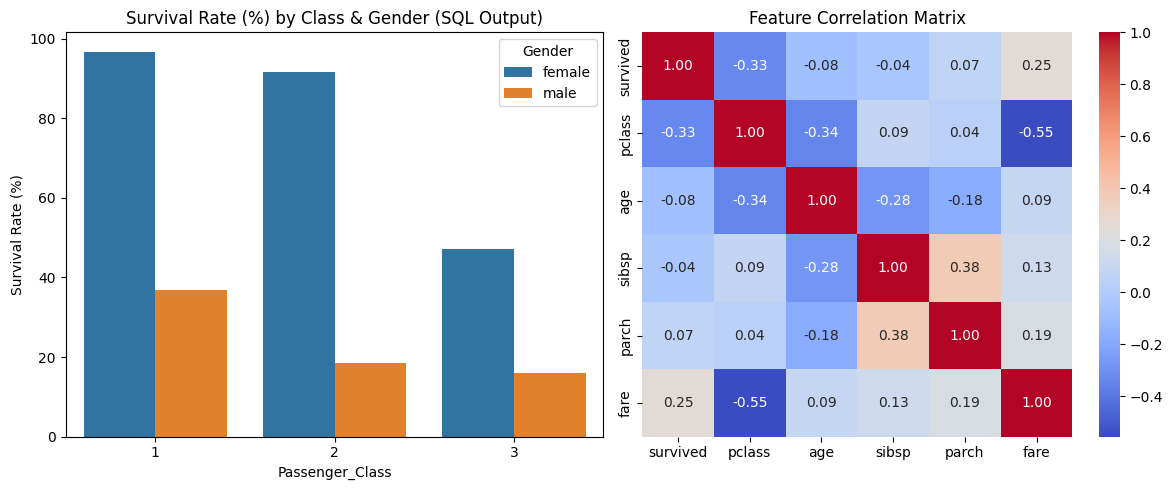

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load & Clean Dataset
df = sns.load_dataset('titanic')
df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df.drop(columns=['deck', 'embark_town', 'alive'], inplace=True)
df.drop_duplicates(inplace=True)

# 2. Load Cleaned Data into SQLite & Run SQL Aggregation Query
conn = sqlite3.connect(':memory:')
df.to_sql('passengers', conn, index=False, if_exists='replace')

sql_query = """
SELECT
    pclass AS Passenger_Class,
    sex AS Gender,
    COUNT(*) AS Total_Passengers,
    ROUND(AVG(age), 1) AS Avg_Age,
    ROUND(AVG(fare), 2) AS Avg_Fare,
    ROUND(AVG(survived) * 100, 1) AS Survival_Rate_Pct
FROM passengers
GROUP BY pclass, sex
ORDER BY pclass ASC, Survival_Rate_Pct DESC;
"""
sql_summary = pd.read_sql_query(sql_query, conn)
print("--- SQL Cohort Analysis ---")
print(sql_summary.to_string(index=False))

# 3. Generate Visualizations
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=sql_summary, x='Passenger_Class', y='Survival_Rate_Pct', hue='Gender', ax=axes[0])
axes[0].set_title('Survival Rate (%) by Class & Gender (SQL Output)')
axes[0].set_ylabel('Survival Rate (%)')

numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1])
axes[1].set_title('Feature Correlation Matrix')

plt.tight_layout()
plt.show()